In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('Customer Sales Business data set.csv')
df.head(10)

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product,Category,Quantity,Unit_Price,Discount_Percent,Sales,Profit,Payment_Mode,Order_Status,Customer_Segment,Return_Status
0,ORD10659,2025-02-22 00:00:00,CUST1140,Anitha Kumar,Female,52.0,Delhi,Delhi,North,Headset,Accessories,4,2011.01,15.0,6837.43,1223.54,Net Banking,Cancelled,Consumer,No
1,ORD10213,2025-12-13 00:00:00,CUST1247,Priya R,Male,28.0,Delhi,Delhi,North,Monitor,Electronics,2,14683.35,5.0,27898.36,4615.54,Credit Card,Returned,Small Business,Returned
2,ORD10421,2025-09-25 00:00:00,CUST1086,Dinesh S,Female,60.0,Madurai,Tamil Nadu,South,Tablet,Electronics,2,18452.84,15.0,31369.83,5826.40,Net Banking,delivered,Small Business,No
3,ORD10108,2025-02-17 00:00:00,CUST1077,Dinesh S,Female,22.0,Kolkata,West Bengal,East,Mobile Phone,Electronics,4,23994.76,5.0,91180.09,13063.16,Debit Card,Cancelled,Corporate,No
4,ORD10344,2025-01-29 00:00:00,CUST1205,Anitha P,Male,35.0,Hyderabad,Telangana,South,Router,Networking,2,3119.17,0.0,6238.34,1160.45,Net Banking,Delivered,Consumer,No
5,ORD10686,2025-12-08 00:00:00,CUST1199,Priya S,Male,28.0,Bengaluru,Karnataka,South,SSD,Storage,-1,6311.88,5.0,29981.43,2926.58,Cash,Shipped,Small Business,No
6,ORD10334,2025-02-08 00:00:00,CUST1049,Karthik R,Male,25.0,Delhi,Delhi,North,Keyboard,Accessories,1,1657.45,10.0,1491.71,245.92,Cash,Delivered,Consumer,No
7,ORD10351,2025-05-10 00:00:00,CUST1157,Vijay R,Male,28.0,Chennai,Tamil Nadu,South,USB Drive,Storage,2,1147.44,10.0,2065.39,215.90,Credit Card,Cancelled,Consumer,No
8,ORD10188,2025-01-23 00:00:00,CUST1003,Harish P,Male,45.0,Delhi,Delhi,North,Router,Networking,1,3218.98,5.0,3058.03,577.85,Credit Card,Delivered,Small Business,No
9,ORD10300,2025-10-11 00:00:00,CUST1064,Santhosh P,Female,45.0,Delhi,Delhi,North,Keyboard,Accessories,2,1780.94,10.0,3205.69,529.70,Net Banking,Cancelled,Small Business,No


In [4]:
df.drop([
    "Return_Status",
    "Order_Status",
    "Payment_Mode",
    "Discount_Percent"
],axis=1,inplace=True)

In [4]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Gender',
       'Age', 'City', 'State', 'Region', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Sales', 'Profit', 'Customer_Segment'],
      dtype='str')

In [5]:
df.dtypes

Order_ID                str
Order_Date              str
Customer_ID             str
Customer_Name           str
Gender                  str
Age                     str
City                    str
State                   str
Region                  str
Product                 str
Category                str
Quantity              int64
Unit_Price          float64
Sales                   str
Profit              float64
Customer_Segment        str
dtype: object

In [6]:
df["Age"]= pd.to_numeric(df["Age"],errors="coerce")
df["Age"]=df["Age"].fillna(df["Age"].median()).astype(int)
df.dtypes

Order_ID                str
Order_Date              str
Customer_ID             str
Customer_Name           str
Gender                  str
Age                   int64
City                    str
State                   str
Region                  str
Product                 str
Category                str
Quantity              int64
Unit_Price          float64
Sales                   str
Profit              float64
Customer_Segment        str
dtype: object

In [7]:
df["Sales"]= pd.to_numeric(df["Sales"],errors="coerce")
df.dtypes

Order_ID                str
Order_Date              str
Customer_ID             str
Customer_Name           str
Gender                  str
Age                   int64
City                    str
State                   str
Region                  str
Product                 str
Category                str
Quantity              int64
Unit_Price          float64
Sales               float64
Profit              float64
Customer_Segment        str
dtype: object

In [8]:
df.isna().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name       18
Gender               0
Age                  0
City                12
State                0
Region               0
Product              0
Category             0
Quantity             0
Unit_Price           7
Sales                6
Profit              10
Customer_Segment     0
dtype: int64

In [9]:
df["Customer_Name"] = df["Customer_Name"].fillna(df["Customer_Name"]).mode()[0]
df.isna().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name        0
Gender               0
Age                  0
City                12
State                0
Region               0
Product              0
Category             0
Quantity             0
Unit_Price           7
Sales                6
Profit              10
Customer_Segment     0
dtype: int64

In [10]:
df["Sales"] = df["Sales"].fillna(df["Sales"]).mode()[0]
df["City"] = df["City"].fillna(df["City"]).mode()[0]
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"]).mode()[0]
df["Profit"] = df["Profit"].fillna(df["Profit"]).mode()[0]
df.isna().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
Gender              0
Age                 0
City                0
State               0
Region              0
Product             0
Category            0
Quantity            0
Unit_Price          0
Sales               0
Profit              0
Customer_Segment    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(20)

In [15]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [16]:
df.to_csv("customer_salse_cleaning_python.csv",index=False)

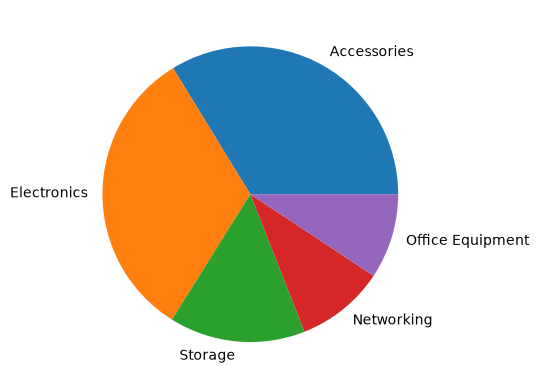

In [30]:
#matplotlib
#1)pie chart
plt.pie(df["Category"].value_counts(), labels=df["Category"].value_counts().index)

plt.show()

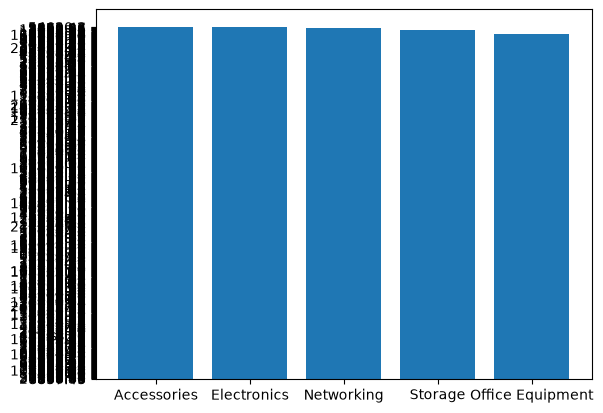

In [ ]:
#2)bar plot
plt.bar(df["Category"], df["Sales"])
plt.show()

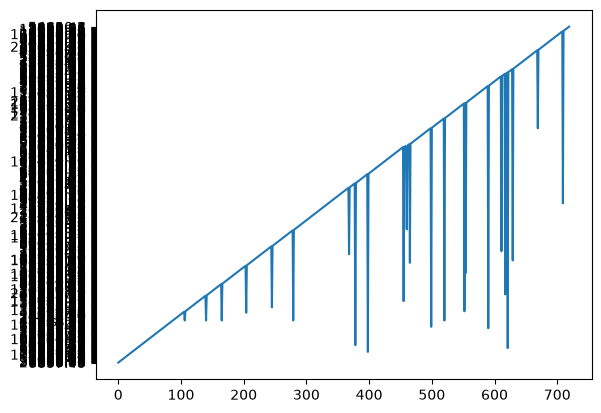

In [5]:
plt.plot(df["Sales"])
plt.show()

In [8]:
#seaborn plots
import seaborn as sns

<Axes: xlabel='Gender', ylabel='count'>

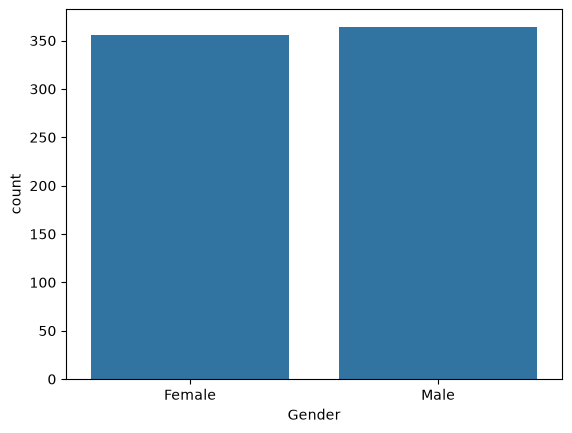

In [9]:
# 1)count plot:gender
sns.countplot(x="Gender",data=df)

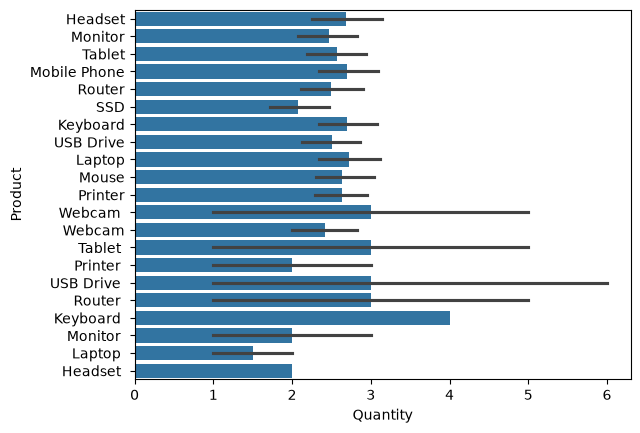

In [ ]:
#2)bar plot : quentity and product

sns.barplot(x="Quantity", y="Product", data=df)
plt.show()

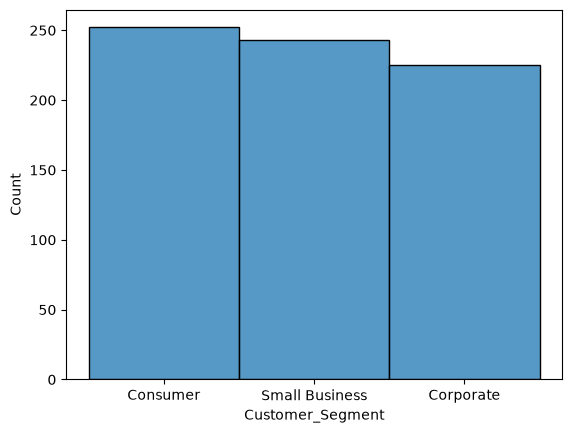

In [10]:
#3)histogram : costomer segment
sns.histplot(df["Customer_Segment"])
plt.show()

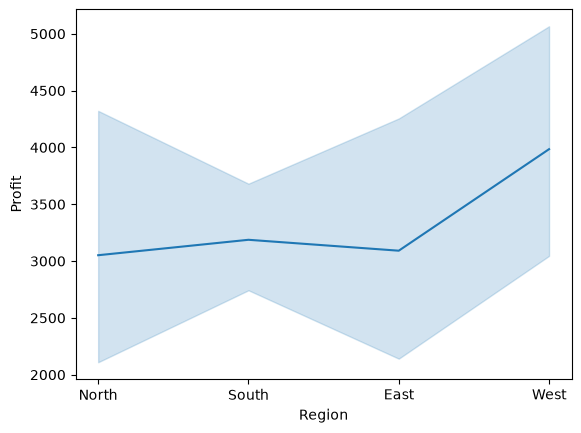

In [ ]:
#4)lineplot
sns.lineplot(x=df["Region"], y=df["Profit"])
plt.show()

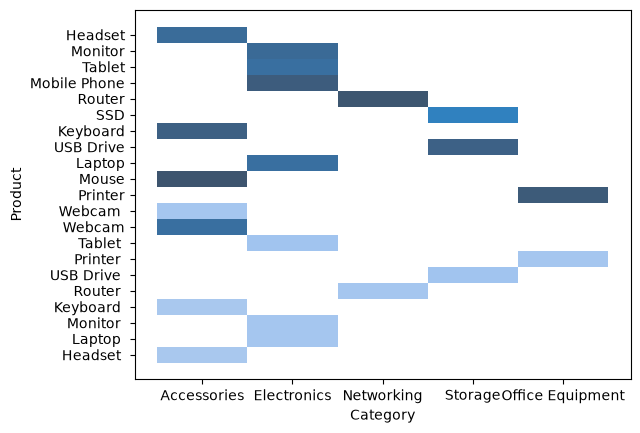

In [ ]:
#5)histplot
sns.histplot(x="Category", y="Product", data=df)
plt.show()